# Extended Data Fig. 3: stationarity, window length and drift controls

d2 = d2 (2024 Euclidean, AR p = 20, 40 ms), labelled "d2". Each panel is drawn by its producer's figure code, the figure captured and cut into single panels (`si_panels.panel`), saved to `../figure_output/supplementary/FigS3/`. Dots are sessions. Stars: *p < 0.05, **p < 0.01, ***p < 0.001, ****p < 0.0001.

- **a** Augmented Dickey-Fuller test (null: a unit root) in each non-overlapping 30 s window: fraction of windows rejecting it (p < 0.05) per session and state (NREM 18, REM 15, Wake θ 12, Wake non-θ 18 sessions with ≥ 5 windows), for the data, a stationary AR(20) surrogate and the data plus a random walk scaled to 1 SD; two-sided paired Wilcoxon signed-rank, data vs each surrogate (`r25_adf_box.py`; `r25_adf_box.csv`).
- **b** Per-session Spearman ρ of d2 with SWR rate on non-overlapping NREM windows of 10 to 60 s (16 sessions; shaded, N/p < 20); two-sided one-sample Wilcoxon signed-rank against 0 (`r25_drift_control_rates.py` on the windows of `window_length_sweep.py`; `window_length_sweep_windows.csv`).
- **c, d** Per-session Spearman ρ of d2 with SWR rate (c, 16 sessions) and barrage rate (d, barrage cohort, 12 sessions), non-overlapping 30 s NREM windows: d2, d2 after removing each window's linear trend, the partial correlation given |trend|, and windows with |trend| < 0.5 SD only; two-sided one-sample Wilcoxon signed-rank against 0 (`r25_drift_control_rates.py`; `r25_drift_control_rates.csv`).
- **e–g** Per-session Spearman ρ of the event-excised d2 with SWR rate (e) and barrage rate (f) (barrage cohort, 12 sessions; ripples and barrages excised) and with replay probability (g, 8 sessions; ripples excised), for the intact window, the glued excised series (event bins dropped, the rest joined, one AR(20) across the joins) and the within-segment estimator (no lag product crosses a join); two-sided one-sample Wilcoxon signed-rank against 0 (`r16_glue_control.py`; `r16_glue_control_windows.csv`, `d2_yw_matlab_match.csv`).

In [1]:
# Data: ../csv/FigS3_drift_control/
from pathlib import Path
import pandas as pd
CSV = Path('..') / 'csv' / 'FigS3_drift_control'


def read_csv(name, **kw):
    """A table of this notebook (round_trip: the floats exactly as written)."""
    return pd.read_csv(CSV / name, float_precision='round_trip', **kw)

import os
import re
import sys
sys.path.insert(0, os.path.abspath('.'))   # figure_scripts/
import matplotlib.pyplot as plt
import final_figs as F                     # print styles, saving, stars
from si_panels import producer, patch, grab, panel   # drawing code's figure -> single panels

plt.rcParams.update({"svg.fonttype": "none", "pdf.fonttype": 42})   # text stays text
RHO = "Spearman ρ"


def pfmt(p):
    """a p value as printed on the figures: never "p=0.000" """
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

## a: unit-root test within windows

NREM      sessions 18, with >= 5 windows 18 (windows/session 254-472)
REM       sessions 16, with >= 5 windows 15 (windows/session 3-24)
THETA     sessions 16, with >= 5 windows 12 (windows/session 1-74)
nonTHETA  sessions 18, with >= 5 windows 18 (windows/session 82-471)
   state          contrast  n_sessions  median_real  median_other  median_diff  n_real_higher  n_real_lower      p
    NREM real - stationary          18       0.9967        0.9966       0.0000              7             8 0.1728
    NREM         real - rw          18       0.9967        0.1698       0.8261             18             0 0.0000
     REM real - stationary          15       0.9333        1.0000       0.0000              2             6 0.3270
     REM         real - rw          15       0.9333        0.0909       0.7500             15             0 0.0006
   THETA real - stationary          12       1.0000        1.0000       0.0000              1             2 0.5000
   THETA         real - rw          1

figure -> ..\csv\FigS3_drift_control\r25_adf_box.png/.svg


saved figure_output\supplementary\FigS3\FigS3_A_adf_stationarity.svg / .png


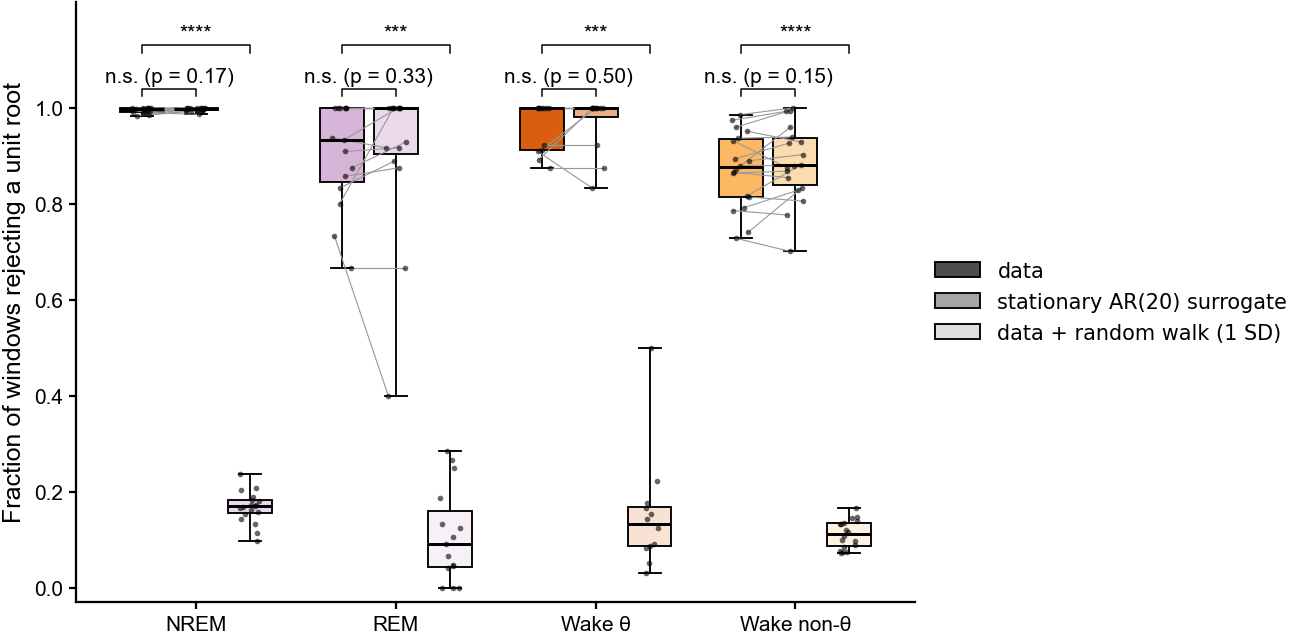

In [2]:
# a: r25_adf_box's figure from its per-session table, its stars by F.stars
M = producer("r25_adf_box_drawing")       # r25_adf_box.py's drawing functions (copied)
M.LOGDIR = M.FIGDIR = str(CSV)
M._stars = F.stars
patch(M, "_p_text", [('return "***" if p < .001 else "**" if p < .01 else "*"', "return _stars(p)")])
# ---- data (../csv) ----
FA = grab(lambda: M.main(read_csv("r25_adf_box.csv")), "r25_adf_box")
# ---- the same from the recordings, with analysis_scripts/: ----
# M = producer("r25_adf_box")             # per_session() of r25_stationarity_windows.csv (r25_stationarity_battery.py)
# FA = grab(M.main, "r25_adf_box")
panel(FA, 0, "FigS3_A_adf_stationarity", 110, 54, ylabel="Fraction of windows rejecting a unit root",
      ticks=lambda s: re.sub(r"\s*\(n = \d+\)", "", s))    # per-state n: in the legend
plt.close(FA)
F.show(F.stem("FigS3_A_adf_stationarity") + ".png")

## b–d: SWR- and barrage-rate relations by window length and under drift control


d2 (2024 Euclidean, p=20, 40 ms) ~ event rate, NREM 30 s non-overlapping windows; session = unit
arms: real | linearly detrended d2 | partial r given |trend| | windows with |trend| < 0.5 SD only

  Fig 2 cohort: d2 ~ ripple rate  (n = 16 sessions)
  arm           Fisher r    ± SE  sign-consistent  signed-rank p
  real            +0.241   0.031       16/16              0.0000
  detrended       +0.167   0.028       16/16              0.0000
  partial         +0.201   0.029       16/16              0.0000
  low-drift       +0.202   0.032       15/16              0.0001
  |trend| ~ rate    -0.178   0.022       15/16              0.0001  (neg count)
  |trend| ~ d2    -0.295   0.031       16/16              0.0000  (neg count)

  Fig 3 cohort: d2 ~ ripple rate  (n = 12 sessions)
  arm           Fisher r    ± SE  sign-consistent  signed-rank p
  real            +0.207   0.037       12/12              0.0005
  detrended       +0.149   0.039        9/12              0.0068
  partial         +0


figure -> ..\csv\FigS3_drift_control\r25_drift_control_rates.png/.svg


saved figure_output\supplementary\FigS3\FigS3_B_swr_rate_by_window_length.svg / .png


saved figure_output\supplementary\FigS3\FigS3_C_swr_rate_drift_control.svg / .png


saved figure_output\supplementary\FigS3\FigS3_D_barr_rate_drift_control.svg / .png


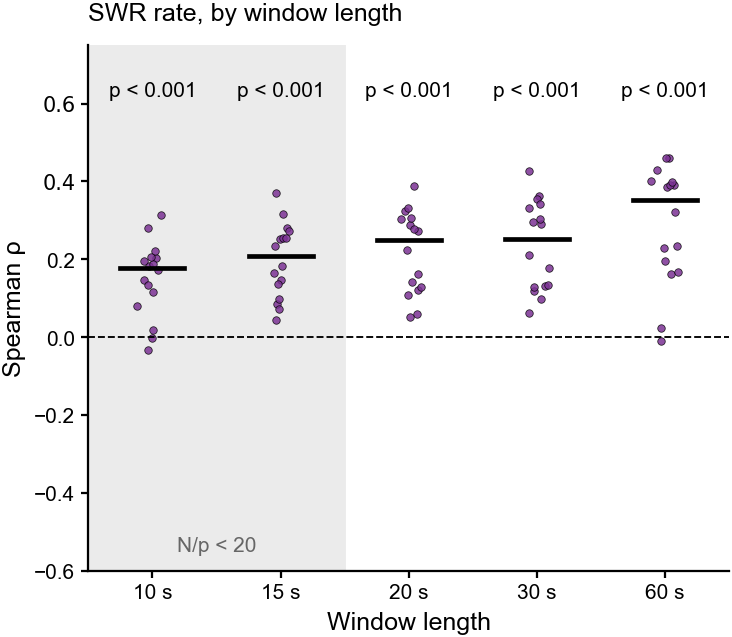

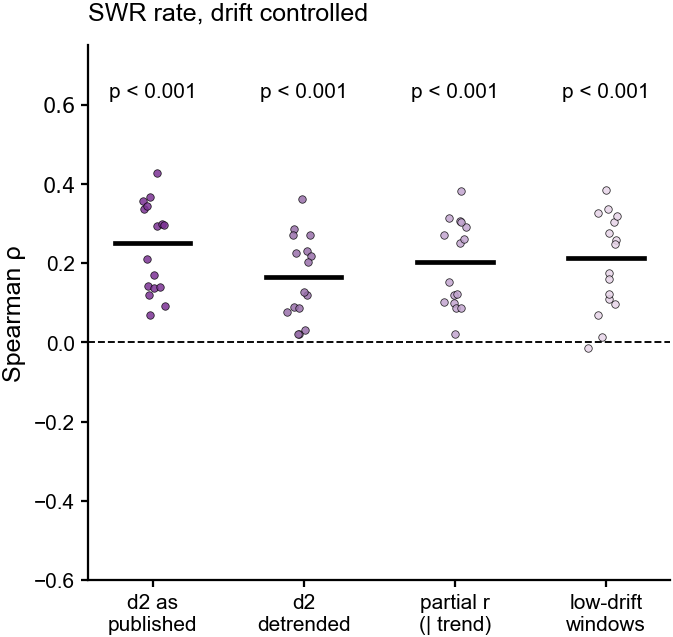

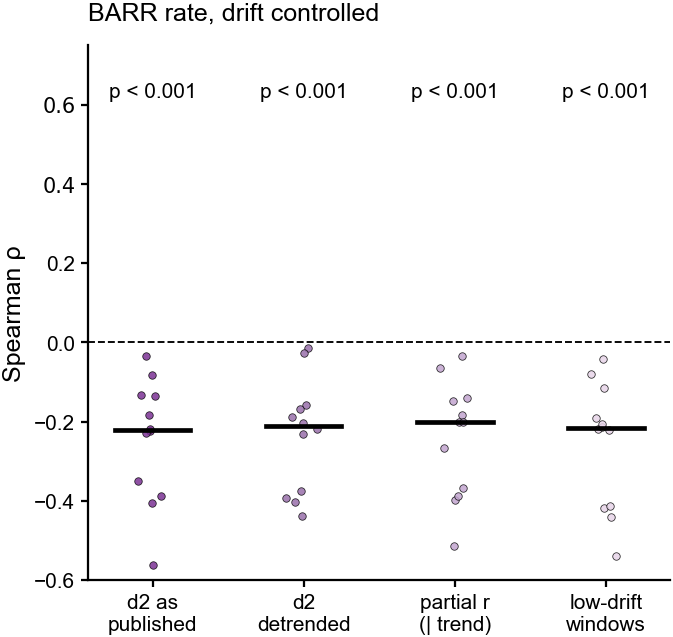

In [3]:
# b-d: r25_drift_control_rates.plot from its per-session table; p values without "p=0.000"
M = producer("r25_drift_control_rates_drawing")   # r25_drift_control_rates.py's drawing functions (copied)
M.LOGDIR = M.FIGDIR = str(CSV)                      # window_length_panel reads window_length_sweep_windows.csv here
M.pfmt = pfmt
patch(M, "window_length_panel", [('\\np={stats.wilcoxon(v).pvalue:.3f}"', '\\n{pfmt(stats.wilcoxon(v).pvalue)}"')])
patch(M, "drift_panel", [('\\np={pw:.3f}"', '\\n{pfmt(pw)}"')])
# ---- data (../csv) ----
R25 = read_csv("r25_drift_control_rates.csv")
# ---- the same from the recordings, with analysis_scripts/: ----
# M = producer("r25_drift_control_rates")
# R25 = pd.read_csv(os.path.join(M.LOGDIR, "r25_drift_control_rates.csv"))
M.report(R25)                                       # Fisher-z mean, sign count and signed-rank p per arm
FBD = grab(lambda: M.plot(R25), "r25_drift_control_rates")
panel(FBD, 0, "FigS3_B_swr_rate_by_window_length", 62, 54, title="SWR rate, by window length",
      xlabel="Window length", ylabel=RHO)
panel(FBD, 1, "FigS3_C_swr_rate_drift_control", 57, 54, title="SWR rate, drift controlled", ylabel=RHO)
panel(FBD, 2, "FigS3_D_barr_rate_drift_control", 57, 54, title="BARR rate, drift controlled", ylabel=RHO)
plt.close(FBD)
for n in ("FigS3_B_swr_rate_by_window_length", "FigS3_C_swr_rate_drift_control", "FigS3_D_barr_rate_drift_control"):
    F.show(F.stem(n) + ".png")

## e–g: event-excised d2, glued and within-segment

barrage cohort: 3775 windows, 12 sessions; median d2 intact 0.0895, glued 0.0917, segments 0.0897; pooled r(glued, segments) 0.955



BARRAGE COHORT: within-session Spearman of d2 with the two event rates (partial = on the other rate)


  arm                   target              rho med     +/-/n        p  partial     +/-        p
  intact                ripple rate          +0.216  12/0 /12    0.0005    0.197  12/0     0.0005
  intact                barrage rate         -0.219   0/12/12    0.0005   -0.201   1/11    0.0010
  excised, glued (current)ripple rate          +0.147  11/1 /12    0.0015    0.139  11/1     0.0024
  excised, glued (current)barrage rate         -0.134   1/11/12    0.0024   -0.135   2/10    0.0122
  excised, within-segmentripple rate          +0.146  10/2 /12    0.0049    0.109   9/3     0.0068
  excised, within-segmentbarrage rate         -0.159   1/11/12    0.0010   -0.161   2/10    0.0034

REPLAY SET (d2_yw_matlab_match.csv, 8 sessions): Spearman with replay probability and ripple rate
  arm                   target              rho med     +/-/n        p  partial     +/-        p
  intact (published)    replay probability   +0.047   6/2 /8     0.0391    0.034   6/2     0.0781
  intact (publ

figure -> ..\csv\FigS3_drift_control\r16_glue_control.png/.svg


saved figure_output\supplementary\FigS3\FigS3_E_glue_swr_rate.svg / .png


saved figure_output\supplementary\FigS3\FigS3_F_glue_barr_rate.svg / .png


saved figure_output\supplementary\FigS3\FigS3_G_glue_replay_probability.svg / .png


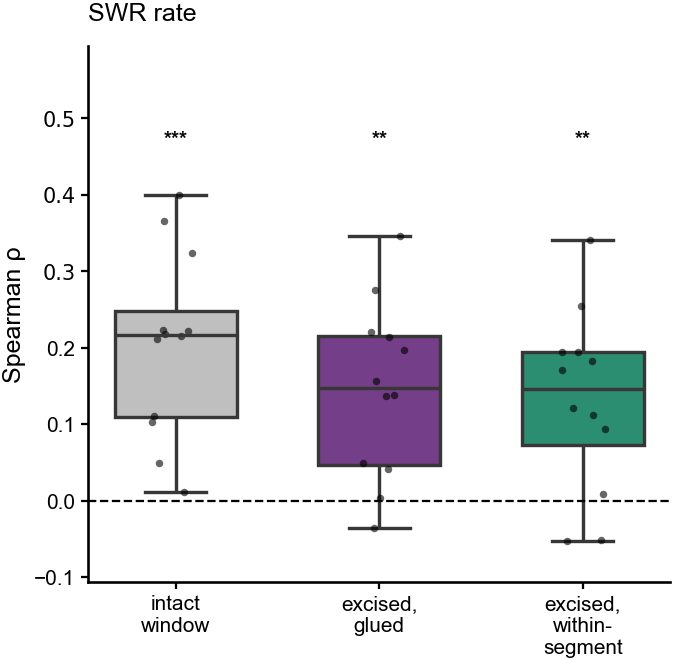

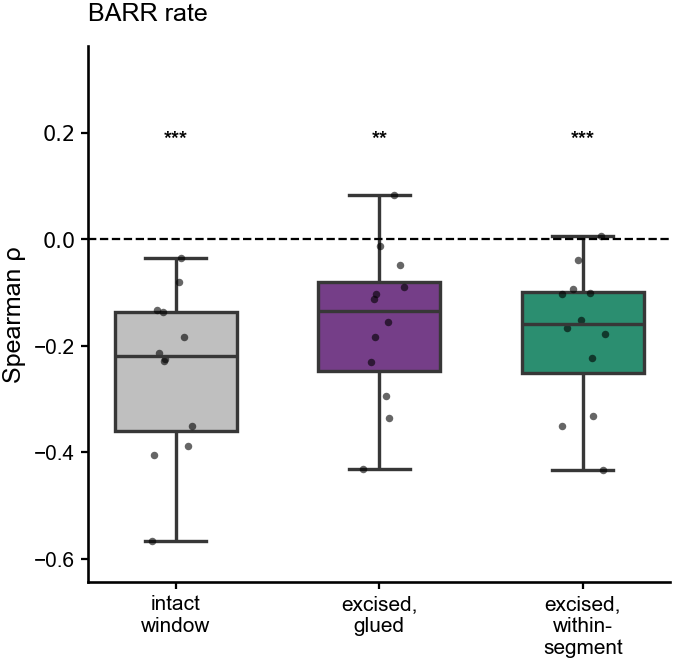

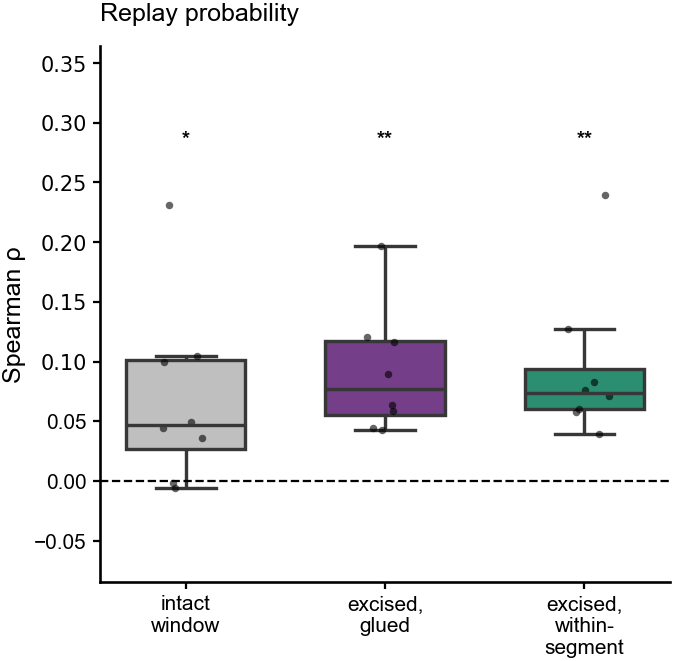

In [4]:
# e-g: r16_glue_control's figure from its two window tables, its stars by F.stars
M = producer("r16_glue_control_drawing")   # r16_glue_control.py's drawing functions (copied)
M.LOGDIR = M.FIGDIR = str(CSV)
M._stars = F.stars
patch(M, "plot", [('st = "***" if pw < .001 else "**" if pw < .01 else "*" if pw < .05 else "n.s."', 'st = _stars(pw)')])
# ---- data (../csv) ----
FEG = grab(lambda: M.main(read_csv("r16_glue_control_windows.csv"), read_csv("d2_yw_matlab_match.csv")),
           "r16_glue_control")
# ---- the same from the recordings, with analysis_scripts/: ----
# M = producer("r16_glue_control")         # RECOMPUTE=1: the barrage cohort's arms from the recordings
# FEG = grab(M.main, "r16_glue_control")
GLUE = lambda s: s.replace("\n(current)", "")             # noqa: E731  the glued arm's tick label
panel(FEG, 0, "FigS3_E_glue_swr_rate", 57, 56, title="SWR rate", ylabel=RHO, ticks=GLUE)
panel(FEG, 1, "FigS3_F_glue_barr_rate", 57, 56, title="BARR rate", ylabel=RHO, ticks=GLUE)
panel(FEG, 2, "FigS3_G_glue_replay_probability", 57, 56, title="Replay probability", ylabel=RHO, ticks=GLUE)
plt.close(FEG)
for n in ("FigS3_E_glue_swr_rate", "FigS3_F_glue_barr_rate", "FigS3_G_glue_replay_probability"):
    F.show(F.stem(n) + ".png")